In [108]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [109]:
# Прочитайте данные (переменную назовите 'df')
df = pd.read_csv('data.csv')

# Вывести несколько первых строк таблицы данных
print(df.head())

         Дата  Склад Контрагент Номенклатура  Количество
0  2018-01-04      1  address_0    product_0           4
1  2018-01-04      1  address_0    product_1           4
2  2018-01-04      1  address_0    product_2           5
3  2018-01-04      1  address_0    product_3          10
4  2018-01-04      1  address_0    product_4           2


Проверяем формат столбцов

In [110]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 301355 entries, 0 to 301354
Data columns (total 5 columns):
 #   Column        Non-Null Count   Dtype
---  ------        --------------   -----
 0   Дата          301355 non-null  str  
 1   Склад         301355 non-null  int64
 2   Контрагент    301355 non-null  str  
 3   Номенклатура  301355 non-null  str  
 4   Количество    301355 non-null  int64
dtypes: int64(2), str(3)
memory usage: 20.0 MB


Сразу переведем столбец "Дата" в правильный формат

In [111]:
df['Дата'] = pd.to_datetime(df['Дата'], errors='coerce')
grouped_df = df.groupby('Дата').size().reset_index(name='Количество_продаж')

Сгруппируйте данные по дате, посчитайте количество продаж

In [112]:
grouped_df = df.groupby('Дата').size().reset_index(name='Количество_продаж')

Вывести несколько первых строк сгруппированных данных

In [90]:
grouped_df.head(5)

,Дата,Количество_продаж
0,2018-01-04,1840
1,2018-01-05,1301
2,2018-01-06,1306
3,2018-01-07,1322
4,2018-01-09,1719


Нарисуйте график продаж у `grouped_df`

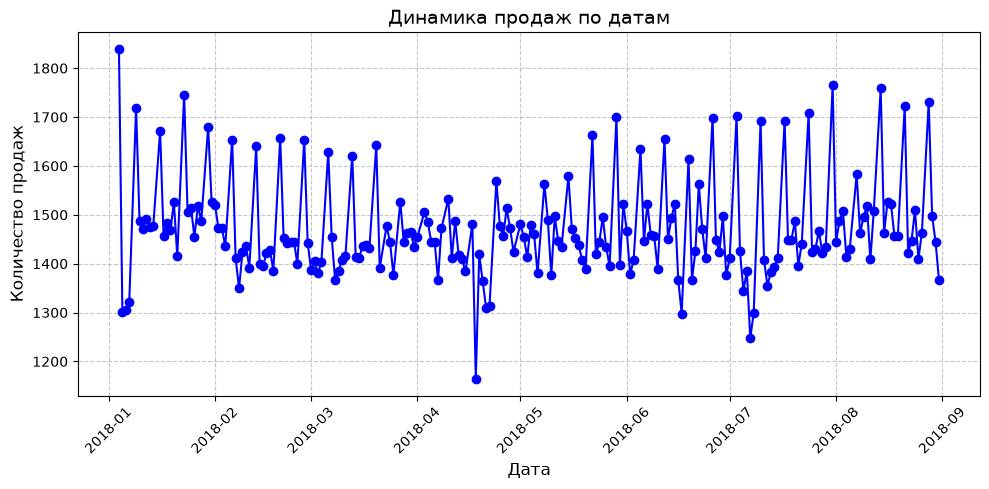

In [74]:
plt.figure(figsize=(10, 5))
plt.plot(grouped_df['Дата'], grouped_df['Количество_продаж'],marker='o',linestyle='-', color='b')

plt.title('Динамика продаж по датам', fontsize=14)
plt.xlabel('Дата', fontsize=12)
plt.ylabel('Количество продаж', fontsize=12)

plt.grid(True, linestyle='--',alpha=0.7)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Опишите что вы видите на графике. Ваша задача - максимально описать график

In [18]:
# na grafike pokazano (2018.01--2018.09) za etot period skolko prodazh bylo 
# x = napisalu datu s nachala january do september 2018 goda
# y = kolichestwo prodazh skolko prodali za etot period
# biznes stabilno bylo v etot period

Найдите строку, у которой максимальный выброс по количеству продаж (нужно найти выброс у `df`)

In [75]:
max_sales = grouped_df['Количество_продаж'].idxmax()

In [76]:
max_sales_row = grouped_df.loc[max_sales]

In [77]:
max_sales_row

Дата                 2018-01-04 00:00:00
Количество_продаж                   1840
Name: 0, dtype: object

Найдите топовый товар по продажам по средам за июнь, июль, август у 3 склада

In [78]:
filtered_df =df[
    (df['Склад'] == 3) &
    (df['Дата'].dt.month.isin([6,7,8])) &
    (df['Дата'].dt.dayofweek == 2)
]
top_product = filtered_df.groupby('Номенклатура')['Количество'].sum().reset_index()
top_product

,Номенклатура,Количество
0,product_0,1324
1,product_1,2267
2,product_10,129
3,product_11,131
4,product_12,129
5,product_13,253
6,product_14,64
7,product_15,230
8,product_16,26
9,product_17,148


In [ ]:
#Скачайте данные по погоде с https://rp5.ru/Архив_погоды_в_Астане
#(скачайте исходные данные, и далее преобразуйте так, чтобы мы имели 
#Дату и Среднюю температуру за день), объедините таблицу температуры с `grouped_df`,
#и нарисуйте график `y=['Количество продаж', 'T']`, где Т это температура. 
#А также отдельно график температуры.

In [95]:
df_temp = pd.read_excel(r"C:\Users\User\Python blok\Data Science\weather.xlsx")

In [113]:
df_temp['Дата'] = pd.to_datetime(
    df_temp['Местное время в Астане'], format='%d.%m.%Y %H:%M'
)

In [114]:
df_daily_temp = (
    df_temp.groupby('Дата')['T']
    .mean()
    .reset_index(name='T')
)

In [115]:
merged_df = pd.merge(grouped_df, df_daily_temp, on='Дата', how='inner')

In [117]:
merged_df

,Дата,Количество_продаж,T


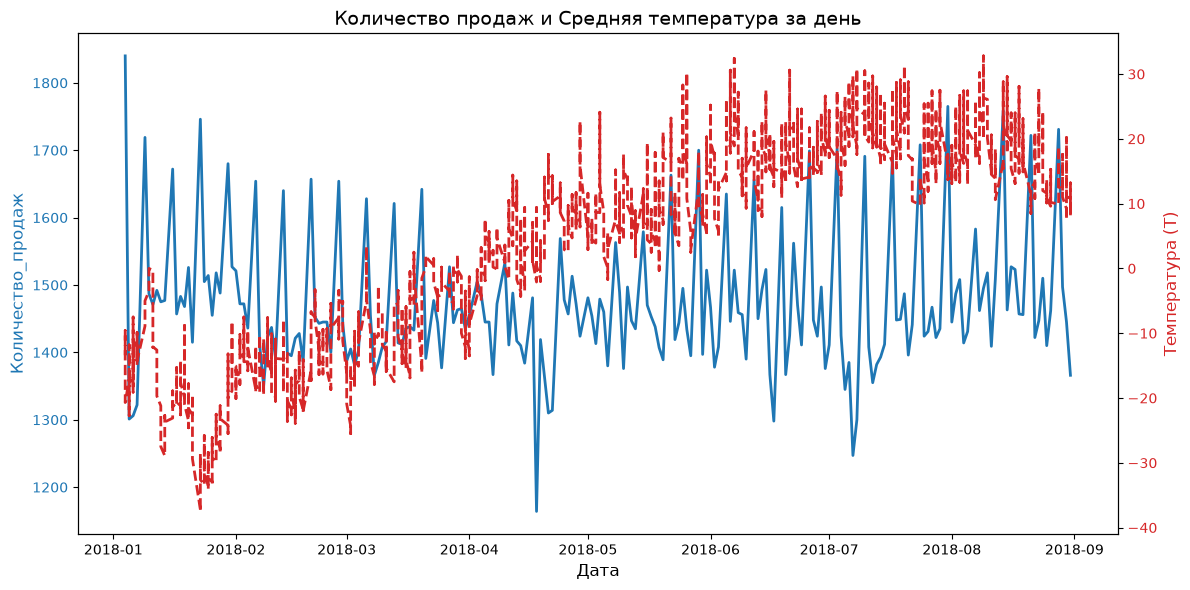

In [124]:
fig, ax1 = plt.subplots(figsize=(12, 6))

# Первая ось (продажи)
color = 'tab:blue'
ax1.set_xlabel('Дата', fontsize=12)
ax1.set_ylabel('Количество_продаж', color=color, fontsize=12)
line1 = ax1.plot(
    merged_df['Дата'],
    merged_df['Количество_продаж'],
    color=color,
    linewidth=2,
    label='Количество_продаж',
)
ax1.tick_params(axis='y', labelcolor=color)

# Вторая ось (температура)
ax2 = ax1.twinx()
color = 'tab:red'
ax2.set_ylabel('Температура (T)', color=color, fontsize=12)
line2 = ax2.plot(
    merged_df['Дата'],
    merged_df['T'],
    color=color,
    linestyle='--',
    linewidth=2,
    label='T (Температура)',
)
ax2.tick_params(axis='y', labelcolor=color)

plt.title('Количество продаж и Средняя температура за день', fontsize=14)
fig.tight_layout()
plt.show()

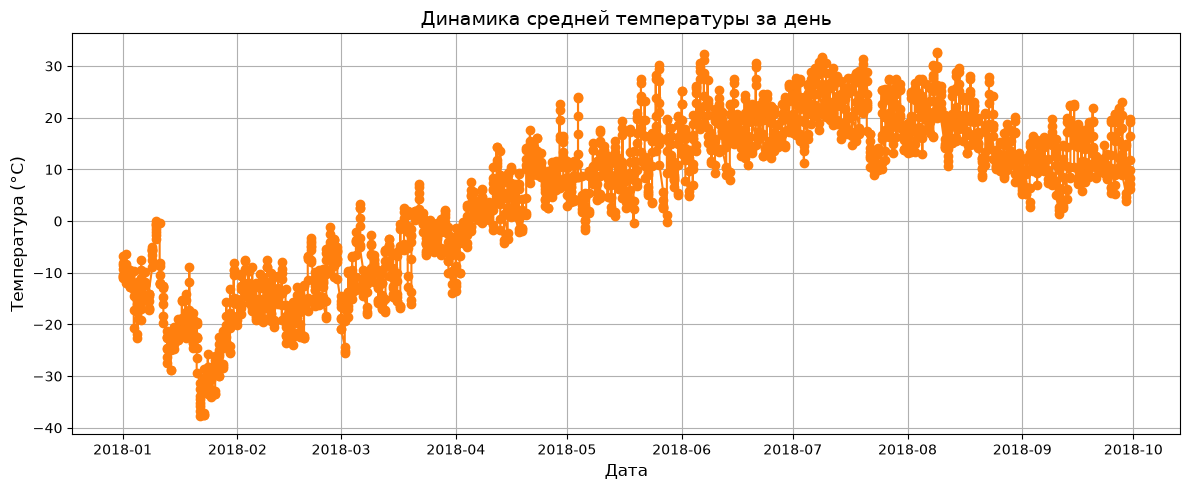

In [125]:
plt.figure(figsize=(12, 5))
plt.plot(
    df_daily_temp['Дата'],
    df_daily_temp['T'],
    color='tab:orange',
    marker='o',
    linestyle='-',
    linewidth=1.5,
)
plt.title('Динамика средней температуры за день', fontsize=14)
plt.xlabel('Дата', fontsize=12)
plt.ylabel('Температура (°C)', fontsize=12)
plt.grid(True)
plt.tight_layout()
plt.show()

In [119]:

print('Размер grouped_df:', grouped_df.shape)
print('Типы данных в grouped_df:\n', grouped_df.dtypes)
print('Первые строки grouped_df:\n', grouped_df.head(2))

print('\nРазмер df_daily_temp:', df_daily_temp.shape)
print('Типы данных в df_daily_temp:\n', df_daily_temp.dtypes)
print('Первые строки df_daily_temp:\n', df_daily_temp.head(2))

# Проверим слияние
merged_df = pd.merge(grouped_df, df_daily_temp, on='Дата', how='inner')
print('\nРазмер merged_df после merge:', merged_df.shape)

Размер grouped_df: (205, 2)
Типы данных в grouped_df:
 Дата                 datetime64[us]
Количество_продаж             int64
dtype: object
Первые строки grouped_df:
         Дата  Количество_продаж
0 2018-01-04               1840
1 2018-01-05               1301

Размер df_daily_temp: (2182, 2)
Типы данных в df_daily_temp:
 Дата    datetime64[us]
T              float64
dtype: object
Первые строки df_daily_temp:
                  Дата     T
0 2018-01-01 02:00:00 -10.4
1 2018-01-01 05:00:00 -10.8

Размер merged_df после merge: (0, 3)


In [122]:
grouped_df['Дата'] = pd.to_datetime(grouped_df['Дата']).dt.normalize()
df_daily_temp['Дата'] = pd.to_datetime(df_daily_temp['Дата']).dt.normalize()

In [123]:
merged_df = pd.merge(grouped_df, df_daily_temp, on='Дата', how='inner')